# Proyecto Demanda: EDA

## Contextual: Análisis de Demanda y Estacionalidad

### Diccionario de Variables y Propósito de Negocio

* **`fecha`, `mes` y `estacion`:** Capturan la estacionalidad del negocio. Permiten comprobar si los incrementos en ventas obedecen a un comportamiento periódico anual o a un crecimiento real de tendencia.
* **`aforo_mensual`:** Indicador clave de la capacidad operativa y afluencia. Permite auditar si el volumen de ventas está limitado por la capacidad física o si refleja la demanda real del mercado tras las restricciones sanitarias.
* **`anomalia`:** Bandera de control para identificar eventos atípicos o disruptivos (cierres por pandemia, crisis). Su auditoría evita que los valores extremos distorsionen los pronósticos futuros.
* **`demanda` (Variable Objetivo):** Representa las ventas históricas. Su análisis longitudinal permitirá comparar los niveles actuales frente al periodo pre y post-pandemia para evaluar una recuperación estructural real.

---

> **💡 Objetivo del Negocio:** Aclarar al propietario si el repunte actual de ventas es un crecimiento consolidado post-pandemia o un ciclo estacional predecible.

## Metadata

In [1]:
#--- Metadata del Proyecto
from datetime import datetime
AUTOR = "Mgtr. Ronald Osorio"
FECHA_MODIFICACION = datetime.now().strftime("%d/%m/%Y %H:%M:%S")

print(f"Autor: {AUTOR}")
print(f"Última modificación: {FECHA_MODIFICACION}\n" + "-"*40)

Autor: Mgtr. Ronald Osorio
Última modificación: 16/10/2026 21:04:41
----------------------------------------


## Entorno

In [2]:
import pandas as pd
import numpy as np

# ruta completa donde se encuentra Utils.py
import sys
sys.path.append('C:/Users/games/OneDrive/DS/Clases/Utils')
from eda_regression import *
from eda_classification import *
from descriptive_analysis import *

## Dataset

### Carga

In [3]:
import os

ruta = os.getcwd()
ruta_xlsx = os.path.join(ruta, 'demanda.xlsx')
df = pd.read_excel(ruta_xlsx)

In [4]:
df

,fecha,demanda,aforo_mensual,anomalia,mes,estacion
0,2010-01-01,35.00,7,0,1,primavera
1,2010-02-01,33.99,7,0,2,invierno
2,2010-03-01,30.00,7,0,3,invierno
3,2010-04-01,36.00,7,0,4,invierno
4,2010-05-01,40.00,8,0,5,otoÃ±o
...,...,...,...,...,...,...
197,2026-06-01,58.00,14,0,6,otoÃ±o
198,2026-07-01,74.00,10,0,7,otoÃ±o
199,2026-08-01,60.00,11,0,8,verano
200,2026-09-01,58.00,10,0,9,verano


## Distribución de Columnas

In [ ]:
target = 'demanda'
df_ids = df[[]]
df_num = df[['aforo_mensual', 'demanda']]
df_bina = df[['anomalia']]
df_tiem = df[['fecha']]
df_cat = df[['estacion']]

# Transformando
df_tiem['fecha'] = pd.to_datetime(df_tiem['fecha']).dt.strftime('%m/%d/%Y')

## Análisis Descriptivo

### Estructura

#### Muestra

In [8]:
df.head(3)

,fecha,demanda,aforo_mensual,anomalia,mes,estacion
0,2010-01-01,35.00,7,0,1,primavera
1,2010-02-01,33.99,7,0,2,invierno
2,2010-03-01,30.00,7,0,3,invierno


In [9]:
df.tail(3)

,fecha,demanda,aforo_mensual,anomalia,mes,estacion
199,2026-08-01,60.0,11,0,8,verano
200,2026-09-01,58.0,10,0,9,verano
201,2026-10-01,61.0,11,0,10,verano


#### Metadata

In [10]:
basic_info(df)


RESUMEN GENERAL DE DATOS
Dimensiones → Filas: 202 | Columnas: 6
                        dtype  mem_default_bytes  mem_deep_bytes  unique  %_unique  zeros  negatives                  min                  max               range
fecha          datetime64[us]               1616            1616     202    100.00      0          0  2010-01-01 00:00:00  2026-10-01 00:00:00  6117 days 00:00:00
demanda               float64               1616            1616      75     37.13      0          0                19.98                 96.0               76.02
aforo_mensual           int64               1616            1616      15      7.43      0          0                  3.0                 17.0                14.0
anomalia                int64               1616            1616       2      0.99    189          0                  0.0                  1.0                 1.0
mes                     int64               1616            1616      12      5.94      0          0                  1.

#### Estadísticas Descriptivas

In [11]:
description(df)


ESTADÍSTICAS DESCRIPTIVAS


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,CV,outliers,outliers_%
fecha,202,2018-05-17 03:19:36.237623,NaN,2010-01-01 00:00:00,2014-03-08 18:00:00,2018-05-16 12:00:00,2022-07-24 06:00:00,2026-10-01 00:00:00,NaN,NaN,NaN,NaN,NaN
demanda,202.0,48.051535,13.195101,19.98,37.26,46.51,57.0,96.0,0.518726,0.377943,0.274603,2.0,0.99
aforo_mensual,202.0,8.80198,2.618419,3.0,7.0,8.0,10.0,17.0,0.663435,0.506005,0.297481,7.0,3.47
anomalia,202.0,0.064356,0.245996,0.0,0.0,0.0,0.0,1.0,3.577287,10.904859,3.822407,13.0,6.44
mes,202.0,6.450495,3.441049,1.0,3.25,6.0,9.0,12.0,0.011838,-1.205695,0.533455,0.0,0.00



### VERIFICACIONES (CHECKS) ###

    ASIMETRÍA / SKEWNESS (|skew|):
    • < 1              : Aproximadamente simétrica → OK
    • 1–2              : Moderadamente sesgada → considerar transformación log/sqrt
    • > 2              : Altamente sesgada → transformación recomendada
    
    CURTOSIS:
    • ≈ 3              : Colas normales (mesocúrtica) → OK
    • < 3              : Colas ligeras (platicúrtica) → OK
    • > 3              : Colas pesadas (leptocúrtica) → verificar outliers
    
    COEFICIENTE DE VARIACIÓN (CV = std/mean):
    • < 0.5            : Baja variabilidad → variable estable
    • 0.5–1.0          : Variabilidad moderada → aceptable
    • > 1.0            : Alta variabilidad → considerar escalado/transformación
    
    OUTLIERS (%):
    • < 5%             : Bajo → OK
    • 5–10%            : Moderado → considerar tratamiento
    • > 10%            : Alto → investigar y potencialmente eliminar/acotar (cap)
    
    LÍMITES DE OUTLIERS:
    • lower_bound = Q1 - 1

## Limpieza de Datos

### Valores Nulos


PATRONES VISUALES DE DATOS FALTANTES


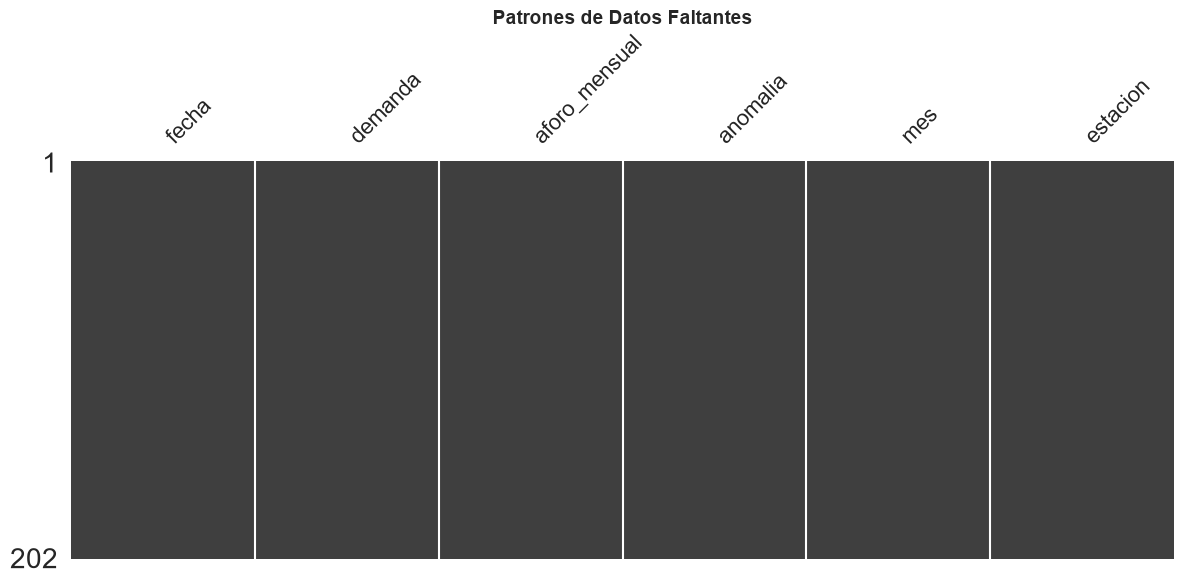


RESUMEN DE DATOS FALTANTES
               null_count  %_missing  fake_nulls fake_values_found  total_missing  %_total
fecha                   0        0.0           0                []              0      0.0
demanda                 0        0.0           0                []              0      0.0
aforo_mensual           0        0.0           0                []              0      0.0
anomalia                0        0.0           0                []              0      0.0
mes                     0        0.0           0                []              0      0.0
estacion                0        0.0           0                []              0      0.0

=== NOTAS ===
-Falsos nulos considerados: "nan", "none", "null", "n/a", "unknown", "na", "nd", "nr", "missing", "not available", "-", "--", "n.a."
-Eliminar la fila si es en la columna target.
-Eliminar columnas con ≥ 15% de valores faltantes, si no vas a usar algotirmos tolerantes a nulos, si los nulos no guardan relación con el ta

In [12]:
null_audit(df)

In [13]:
null_smart_dendrogram(df)

No se puede crear el dendrograma. Columnas con nulos: 0


In [14]:
null_smart_heatmap(df)

No se puede crear el mapa de calor. Columnas con nulos: 0


In [15]:
get_missing_raw_report(df, threshold=0.30)

No se encontraron filas que superen el umbral de valores faltantes.


### Duplicados

In [16]:
check_duplicates(df, subset = None)


ANÁLISIS DE DUPLICADOS
Filas con None duplicado: 0 (0.00%)
✓ No se encontraron duplicados


In [17]:
df = df.drop_duplicates(subset=None, keep='first')

### Valores Atípicos (Outliers)


Generando matriz de Outliers (Boxplots)...


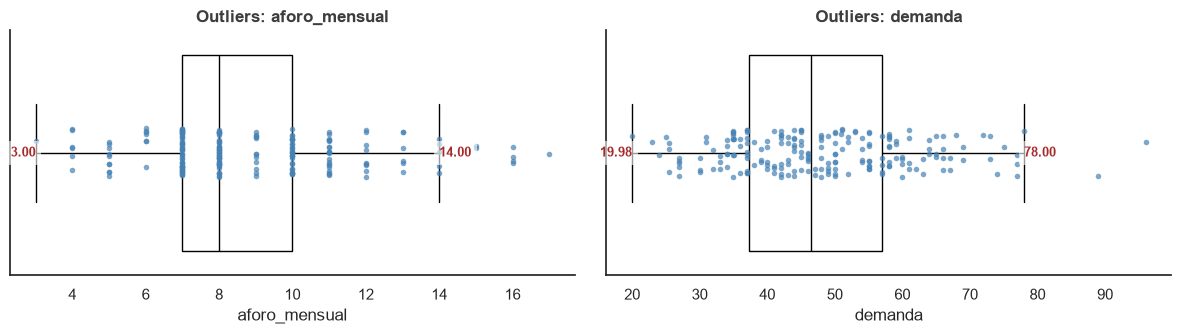

In [18]:
plot_regression_outliers(df_num, None)

## EDA (Análisis Exploratorio de Datos)

### Variable Objetivo

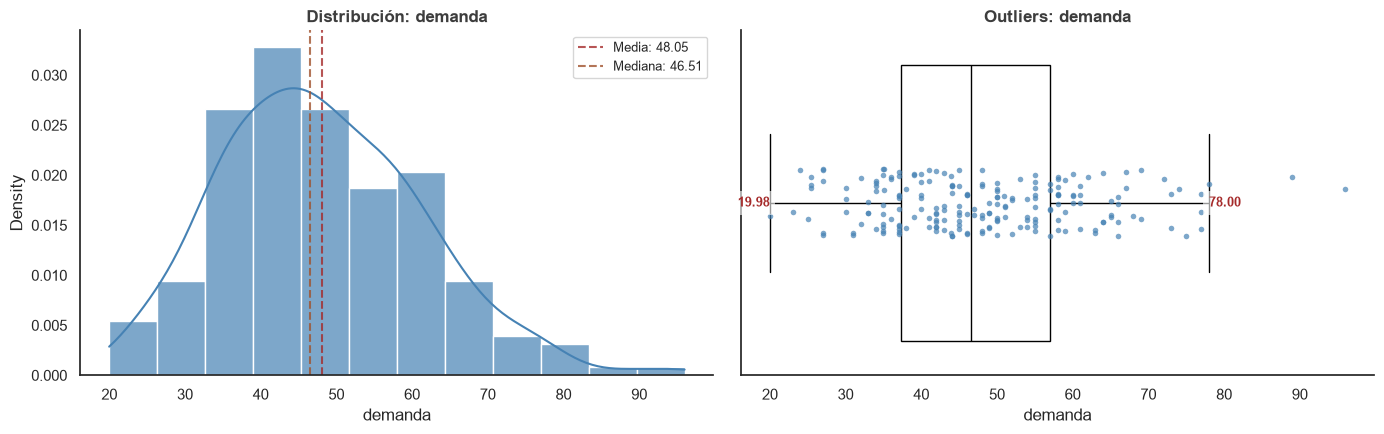

In [19]:
plot_target_reg(df, target)

### Análisis Univariado

#### Distribuciones (Variables Numéricas)

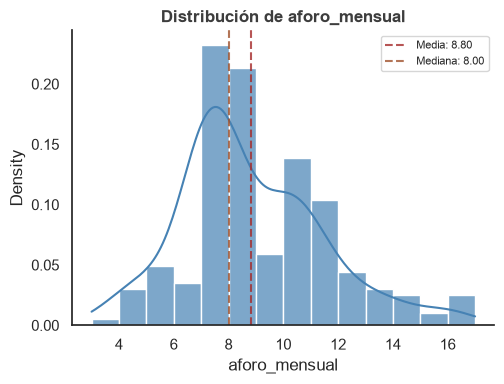


╔════════════════════════════════════════════════════════════════════════════╗
║                   LISTA DE VERIFICACIÓN DE DISTRIBUCIÓN                    ║
╠════════════════════════════════════════════════════════════════════════════╣
║ Distribución          → Campana            → OK para modelos lineales      ║
║ Asimetría (Skewness)  → Colas largas       → Aplicar log1p o boxcox        ║
║ Outliers              → Extremos en colas  → Eliminar (errores) o transf.  ║
║ Densidad              → Zonas dispersas    → Confirmar con outliers        ║
║ Escala                → Rangos distintos   → Estandarizar (StandardScaler) ║
║ Límites/Censura       → Barras verticales  → Eliminar (pocos) o categorizar║
║ Multimodal            → Múltiples picos    → Revisar clústeres geográficos ║
║ Naturaleza            → Continua a categ.  → Considerar trat. categórico   ║
╚════════════════════════════════════════════════════════════════════════════╝
    


In [20]:
plot_all_numeric_distributions_reg(df_num, target)

#### Frecuencias de Variables Binarias

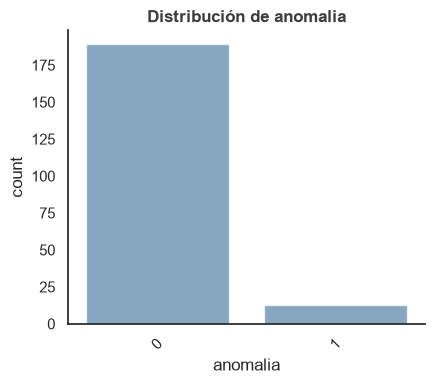

In [21]:
plot_categorical_counts_reg(df_bina, target, max_cat=10)

#### Frecuencias de Variables Categóricas

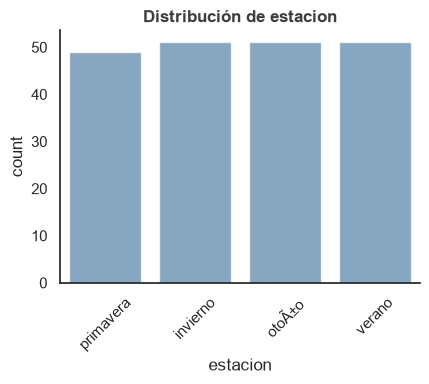

In [22]:
plot_categorical_counts_reg(df_cat, target, max_cat=10)

### Análisis Bivariado

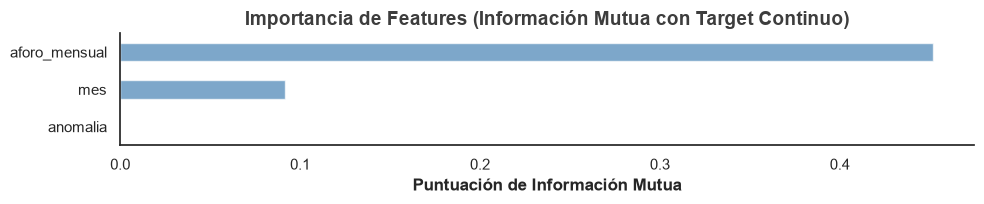

In [23]:
plot_feature_importance_min_reg(df, target)

#### Variables Numéricas vs Variable Objetivo

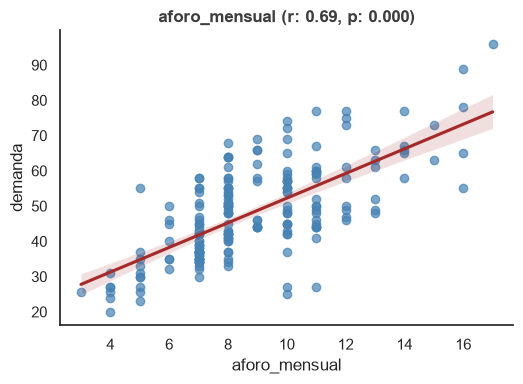

In [24]:
plot_relational_grid_reg(df_num, target)

#### Variables Binarias vs Variable Objetivo
Ninguna

#### Variables Categóricas vs Variable Objetivo

In [25]:
get_categorical_to_numeric_report(df, target)

,Feature,Max_Concentration,P_Value_Kruskal,Is_Significant,MI_Score,Verdict
0,estacion,25.25%,0.0002,YES,0.15698,KEEP



Generando matriz Categórica vs Continua...


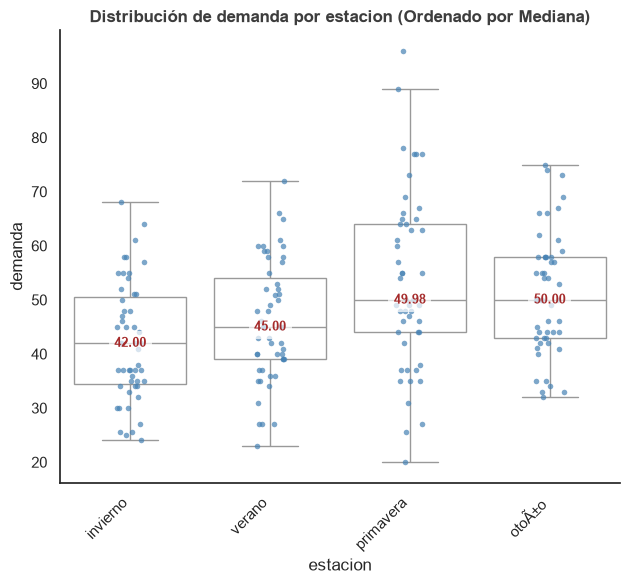

In [26]:
df['fecha'] = pd.to_datetime(df['fecha']) # <-- se le pone para que plot_categorical, no confunda fecha con string
plot_categorical_vs_target_reg(df, target)

#### Variables Categóricas vs Variable Categóricas (opcional)
Ninguna

### Análisis Multivariado

#### Variables con Fechas

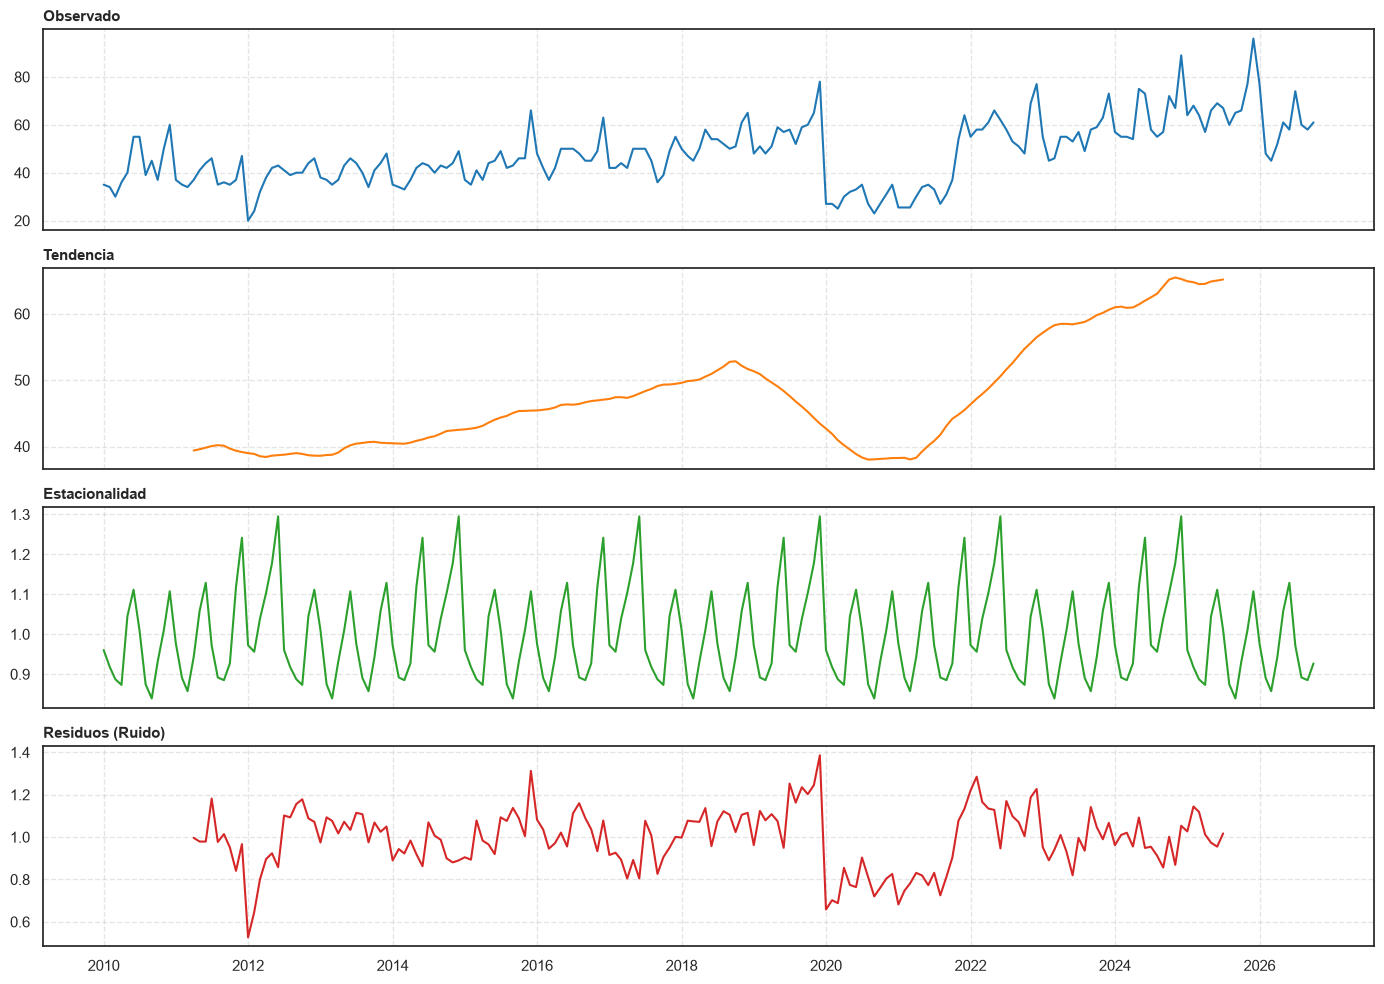

In [27]:
plot_seasonal_decompose(df, column='demanda')

#### Variables Numéricas

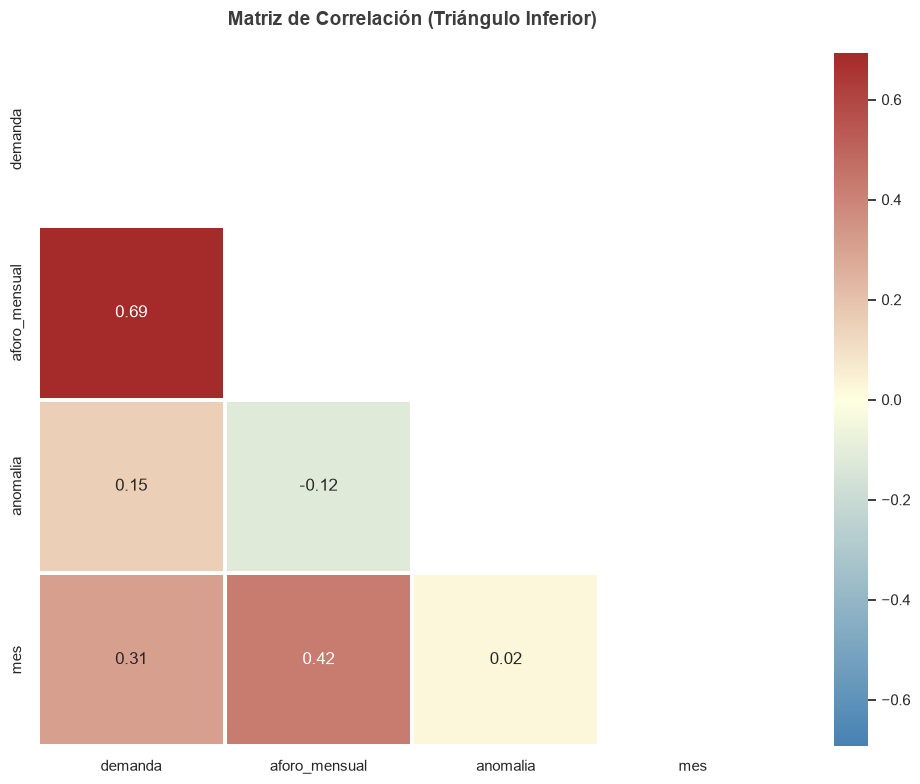

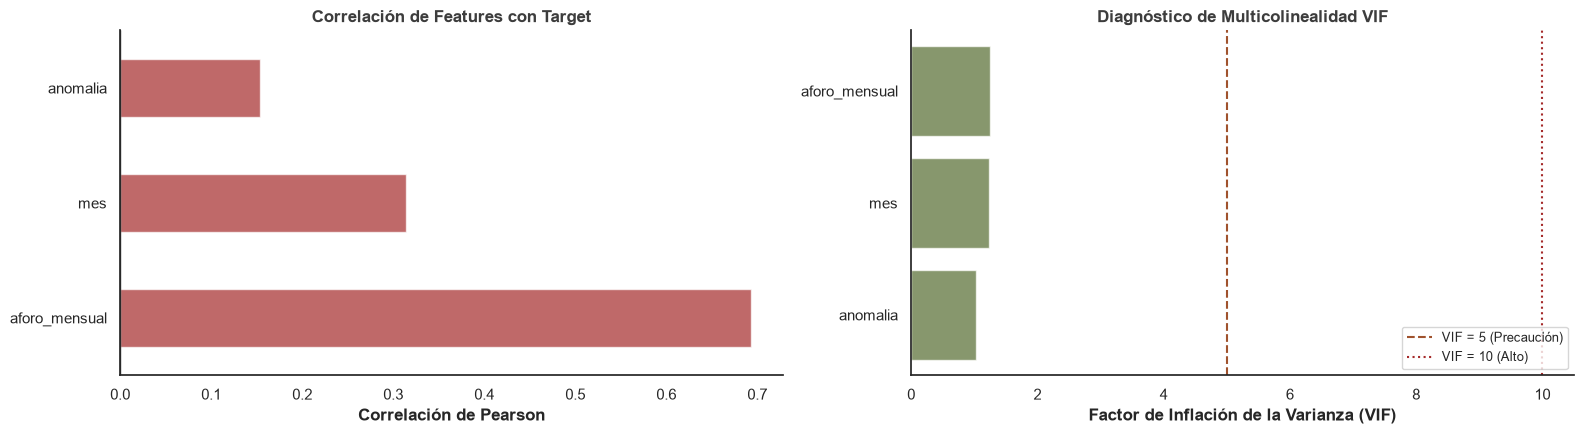


╔════════════════════════════════════════════════════════════════════════════╗
║                     GUÍA DE RESOLUCIÓN DE VIF                              ║
╠════════════════════════════════════════════════════════════════════════════╣
║ Regla práctica: VIF < 5 (Bueno) | VIF 5-10 (Precaución) | VIF > 10 (Elim.) ║
║ NO ELIMINAR si es importante por teoría, si se usan árboles o si           ║
║ se usa Ridge/Lasso (manejan VIF automáticamente). Árboles son inmunes a VIF║
╚════════════════════════════════════════════════════════════════════════════╝
    


In [28]:
plot_numeric_correlation_reg(df, target)

In [29]:
eda_pca(df_num)

=== EVALUACIÓN DE FACTORABILIDAD PARA PCA ===
KMO Global: 0.5000 (Aceptable si > 0.60)
Bartlett p-valor: 2.7198e-30 (Significativo si < 0.05)

=== FACTOR DE INFLACIÓN DE LA VARIANZA (VIF) ===
(VIF aceptable si es < 10)
     Variable      VIF
aforo_mensual 1.926505
      demanda 1.926505


## Descarga

In [30]:
df.to_csv("demanda_post_EDA.csv", index=False)
df

,fecha,demanda,aforo_mensual,anomalia,mes,estacion
0,2010-01-01,35.00,7,0,1,primavera
1,2010-02-01,33.99,7,0,2,invierno
2,2010-03-01,30.00,7,0,3,invierno
3,2010-04-01,36.00,7,0,4,invierno
4,2010-05-01,40.00,8,0,5,otoÃ±o
...,...,...,...,...,...,...
197,2026-06-01,58.00,14,0,6,otoÃ±o
198,2026-07-01,74.00,10,0,7,otoÃ±o
199,2026-08-01,60.00,11,0,8,verano
200,2026-09-01,58.00,10,0,9,verano
